# Importing required library

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("darkgrid")
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, VotingClassifier
from xgboost import XGBClassifier, plot_tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import KFold
from sklearn.metrics import confusion_matrix, classification_report, f1_score, recall_score, precision_score, accuracy_score
%matplotlib inline

In [2]:
df = pd.read_csv('/Users/abhimanyu_yadav/Desktop/DataSet/Diabetes/diabetes_data.csv')
df

,Age,Sex,HighChol,CholCheck,BMI,Smoker,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,GenHlth,MentHlth,PhysHlth,DiffWalk,Stroke,HighBP,Diabetes
0,4.0,1.0,0.0,1.0,26.0,0.0,0.0,1.0,0.0,1.0,0.0,3.0,5.0,30.0,0.0,0.0,1.0,0.0
1,12.0,1.0,1.0,1.0,26.0,1.0,0.0,0.0,1.0,0.0,0.0,3.0,0.0,0.0,0.0,1.0,1.0,0.0
2,13.0,1.0,0.0,1.0,26.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,10.0,0.0,0.0,0.0,0.0
3,11.0,1.0,1.0,1.0,28.0,1.0,0.0,1.0,1.0,1.0,0.0,3.0,0.0,3.0,0.0,0.0,1.0,0.0
4,8.0,0.0,0.0,1.0,29.0,1.0,0.0,1.0,1.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70687,6.0,0.0,1.0,1.0,37.0,0.0,0.0,0.0,0.0,1.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0,1.0
70688,10.0,1.0,1.0,1.0,29.0,1.0,1.0,0.0,1.0,1.0,0.0,2.0,0.0,0.0,1.0,0.0,0.0,1.0
70689,13.0,0.0,1.0,1.0,25.0,0.0,1.0,0.0,1.0,0.0,0.0,5.0,15.0,0.0,1.0,0.0,1.0,1.0
70690,11.0,0.0,1.0,1.0,18.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0.0,1.0,0.0,1.0,1.0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70692 entries, 0 to 70691
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Age                   70692 non-null  float64
 1   Sex                   70692 non-null  float64
 2   HighChol              70692 non-null  float64
 3   CholCheck             70692 non-null  float64
 4   BMI                   70692 non-null  float64
 5   Smoker                70692 non-null  float64
 6   HeartDiseaseorAttack  70692 non-null  float64
 7   PhysActivity          70692 non-null  float64
 8   Fruits                70692 non-null  float64
 9   Veggies               70692 non-null  float64
 10  HvyAlcoholConsump     70692 non-null  float64
 11  GenHlth               70692 non-null  float64
 12  MentHlth              70692 non-null  float64
 13  PhysHlth              70692 non-null  float64
 14  DiffWalk              70692 non-null  float64
 15  Stroke             

In [4]:
df.describe()

,Age,Sex,HighChol,CholCheck,BMI,Smoker,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,GenHlth,MentHlth,PhysHlth,DiffWalk,Stroke,HighBP,Diabetes
count,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000,70692.000000
mean,8.584055,0.456997,0.525703,0.975259,29.856985,0.475273,0.147810,0.703036,0.611795,0.788774,0.042721,2.837082,3.752037,5.810417,0.252730,0.062171,0.563458,0.500000
std,2.852153,0.498151,0.499342,0.155336,7.113954,0.499392,0.354914,0.456924,0.487345,0.408181,0.202228,1.113565,8.155627,10.062261,0.434581,0.241468,0.495960,0.500004
min,1.000000,0.000000,0.000000,0.000000,12.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7.000000,0.000000,0.000000,1.000000,25.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,9.000000,0.000000,1.000000,1.000000,29.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.500000
75%,11.000000,1.000000,1.000000,1.000000,33.000000,1.000000,0.000000,1.000000,1.000000,1.000000,0.000000,4.000000,2.000000,6.000000,1.000000,0.000000,1.000000,1.000000
max,13.000000,1.000000,1.000000,1.000000,98.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,5.000000,30.000000,30.000000,1.000000,1.000000,1.000000,1.000000


# What are the Features?

**Age** - 13-level age category (_AGEG5YR see codebook) 1 = 18-24 9 = 60-64 13 = 80 or older

**Sex** - patient's gender (1: male; 0: female).

**HighChol** - 0 = no high cholesterol 1 = high cholesterol

**CholCheck** - 0 = no cholesterol check in 5 years 1 = yes cholesterol check in 5 years

**BMI** - Body Mass Index

**Smoker** - Have you smoked at least 100 cigarettes in your entire life? [Note: 5 packs = 100 cigarettes] 0 = no 1 = yes

**HeartDiseaseorAttack** - coronary heart disease (CHD) or myocardial infarction (MI) 0 = no 1 = yes

**PhysActivity** - physical activity in past 30 days - not including job 0 = no 1 = yes

**Fruits** - Consume Fruit 1 or more times per day 0 = no 1 = yes

**Veggies** - Consume Vegetables 1 or more times per day 0 = no 1 = yes

**HvyAlcoholConsump** - (adult men >=14 drinks per week and adult women>=7 drinks per week) 0 = no 1 = yes

**GenHlth** - Would you say that in general your health is: scale 1-5 1 = excellent 2 = very good 3 = good 4 = fair 5 = poor

**MentHlth** - days of poor mental health scale 1-30 days

**PhysHlth** - physical illness or injury days in past 30 days scale 1-30

**DiffWalk** - Do you have serious difficulty walking or climbing stairs? 0 = no 1 = yes

**Stroke** - you ever had a stroke. 0 = no, 1 = yes

**HighBP** - 0 = no high, BP 1 = high BP

**Diabetes (Target feature)** - 0 = no diabetes, 1 = diabetes.

# EDA

In [5]:
missing = df.isnull().sum()
missing_per = (missing/df.shape[0])*100
colm = {'Missing Values': missing, 'Missing Percentage': missing_per}
pd.DataFrame(colm)

,Missing Values,Missing Percentage
Age,0,0.0
Sex,0,0.0
HighChol,0,0.0
CholCheck,0,0.0
BMI,0,0.0
Smoker,0,0.0
HeartDiseaseorAttack,0,0.0
PhysActivity,0,0.0
Fruits,0,0.0
Veggies,0,0.0


In [6]:
df.shape

(70692, 18)

In [7]:
df['Diabetes'].value_counts()

0.0    35346
1.0    35346
Name: Diabetes, dtype: int64

# Graphical Analysis

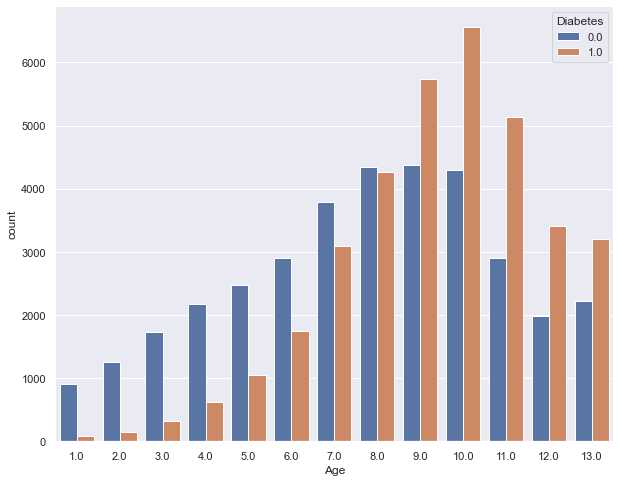

In [8]:
plt.figure(figsize=(10,8))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.countplot(data=df, x='Age', hue='Diabetes')
plt.show()

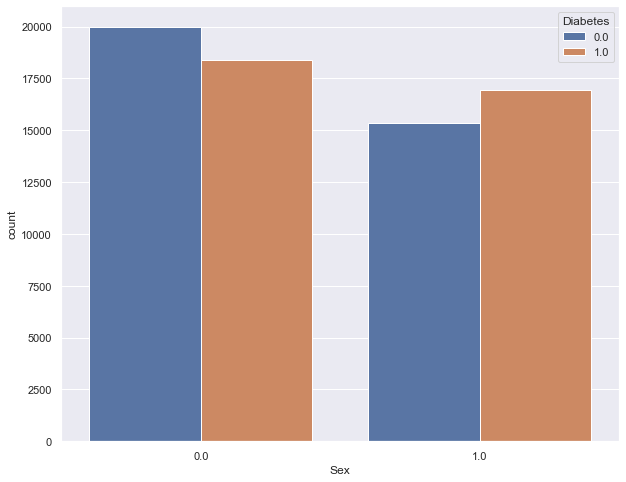

In [9]:
plt.figure(figsize=(10,8))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.countplot(data=df, x='Sex', hue='Diabetes')
plt.show()

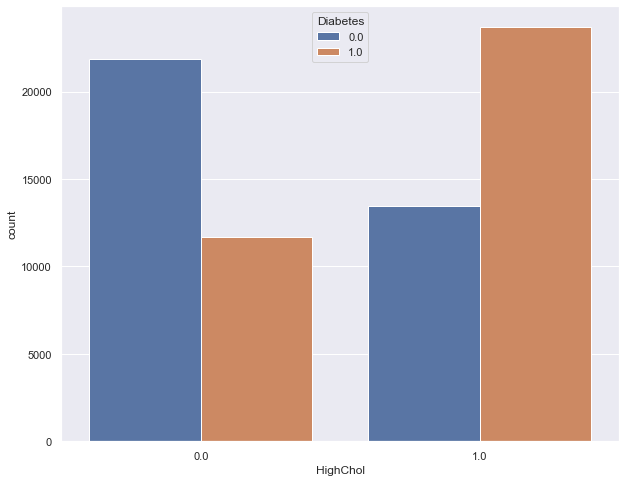

In [10]:
plt.figure(figsize=(10,8))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.countplot(data=df, x='HighChol', hue='Diabetes')
plt.show()

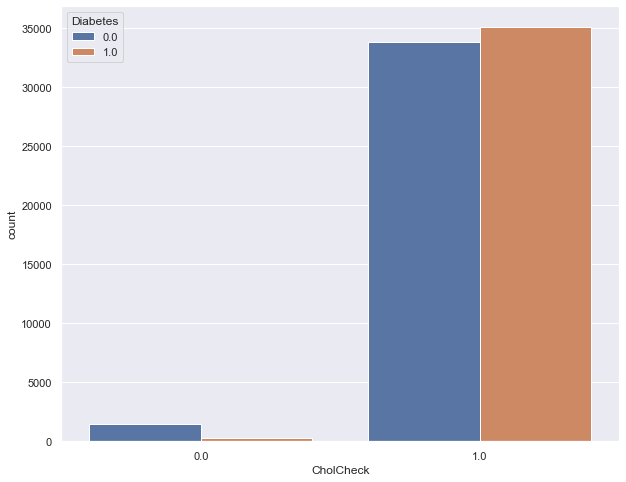

In [11]:
plt.figure(figsize=(10,8))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.countplot(data=df, x='CholCheck', hue='Diabetes')
plt.show()

In [12]:
df.columns

Index(['Age', 'Sex', 'HighChol', 'CholCheck', 'BMI', 'Smoker',
       'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
       'HvyAlcoholConsump', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk',
       'Stroke', 'HighBP', 'Diabetes'],
      dtype='object')

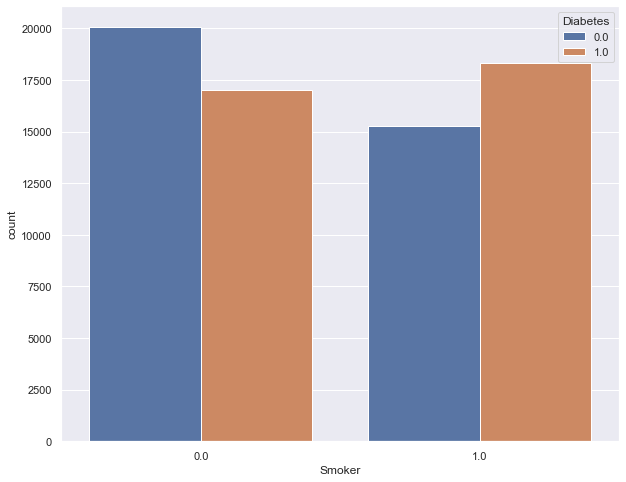

In [13]:
plt.figure(figsize=(10,8))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.countplot(data=df, x='Smoker', hue='Diabetes')
plt.show()

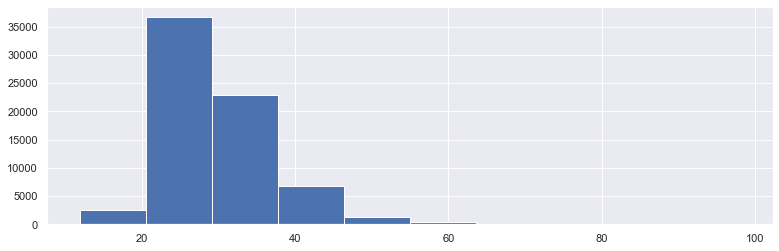

In [14]:
plt.figure(figsize=(13,4))
plt.hist(df["BMI"])
plt.show()

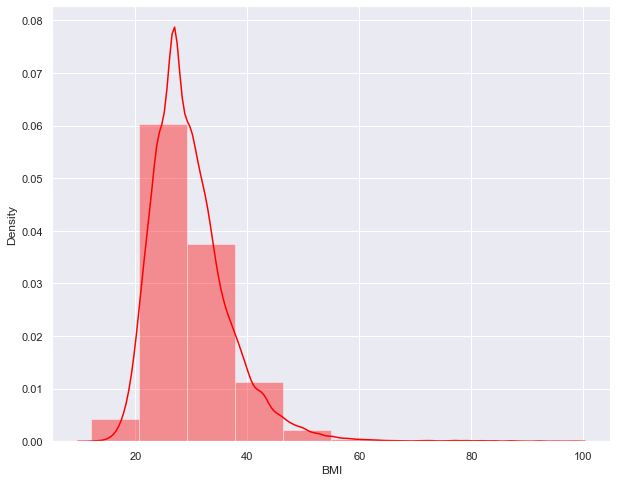

In [15]:
plt.figure(figsize=(10,8))
sns.distplot(df["BMI"], kde=True, bins=10, color='red')
plt.show()

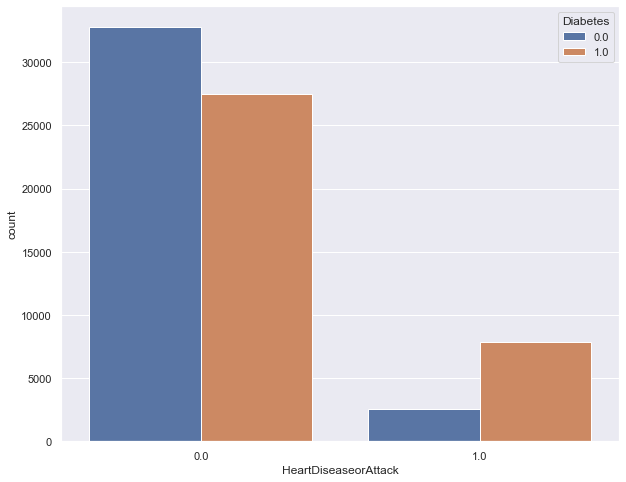

In [16]:
plt.figure(figsize=(10,8))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.countplot(data=df, x='HeartDiseaseorAttack', hue='Diabetes')
plt.show()

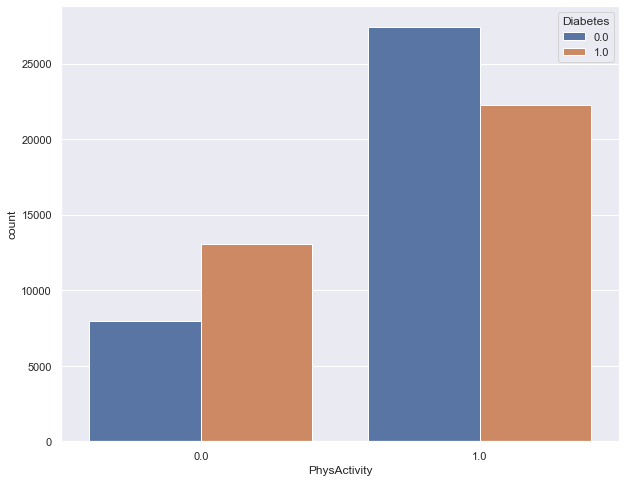

In [17]:
plt.figure(figsize=(10,8))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.countplot(data=df, x='PhysActivity', hue='Diabetes')
plt.show()

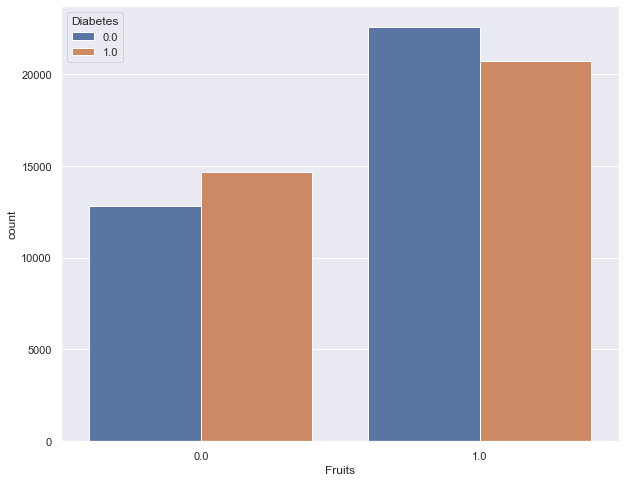

In [18]:
plt.figure(figsize=(10,8))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.countplot(data=df, x='Fruits', hue='Diabetes')
plt.show()

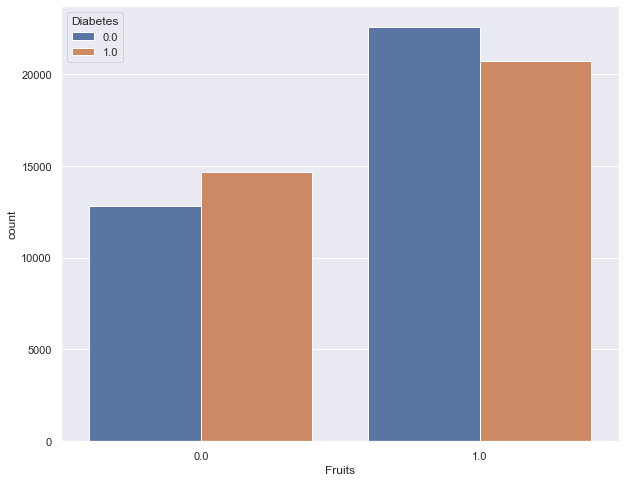

In [19]:
plt.figure(figsize=(10,8))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.countplot(data=df, x='Fruits', hue='Diabetes')
plt.show()

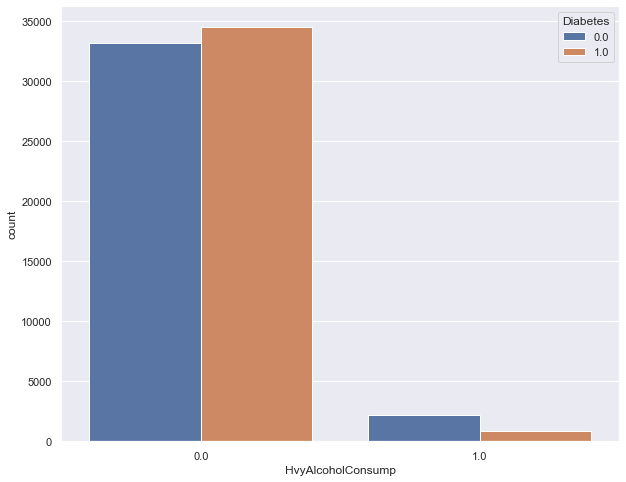

In [20]:
plt.figure(figsize=(10,8))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.countplot(data=df, x='HvyAlcoholConsump', hue='Diabetes')
plt.show()

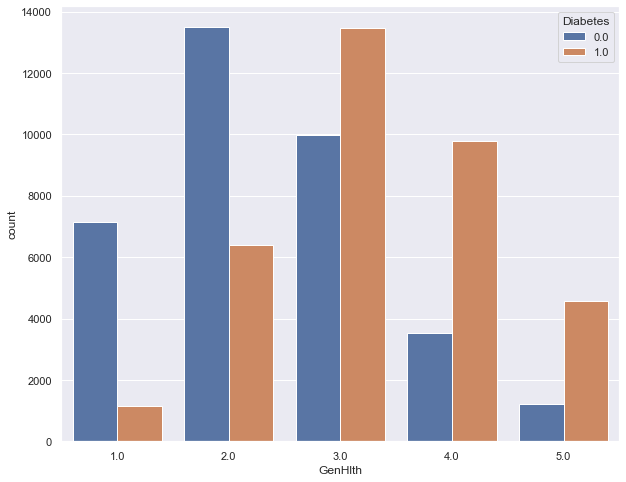

In [21]:
plt.figure(figsize=(10,8))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.countplot(data=df, x='GenHlth', hue='Diabetes')
plt.show()

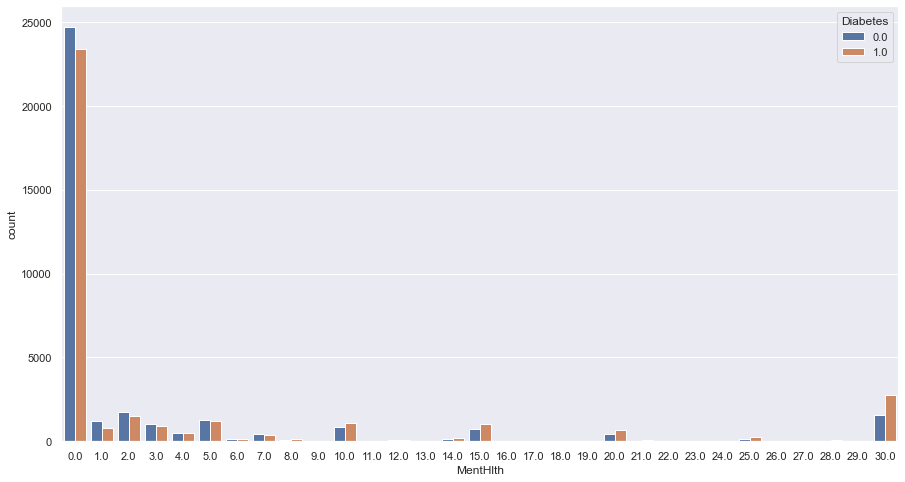

In [22]:
plt.figure(figsize=(15,8))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.countplot(data=df, x='MentHlth', hue='Diabetes')
plt.show()

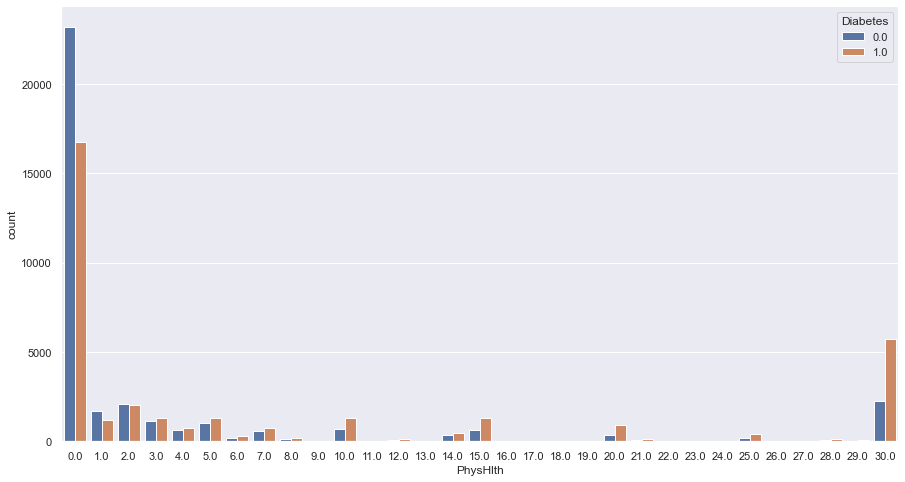

In [23]:
plt.figure(figsize=(15,8))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.countplot(data=df, x='PhysHlth', hue='Diabetes')
plt.show()

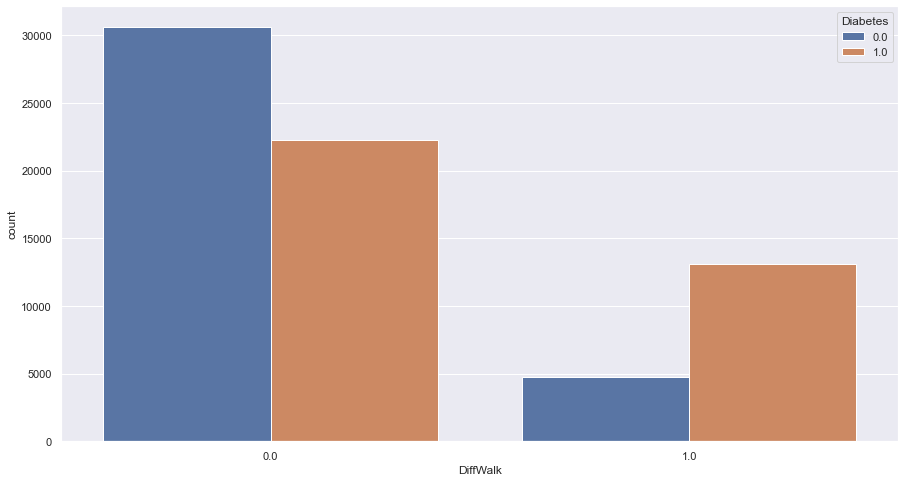

In [24]:
plt.figure(figsize=(15,8))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.countplot(data=df, x='DiffWalk', hue='Diabetes')
plt.show()

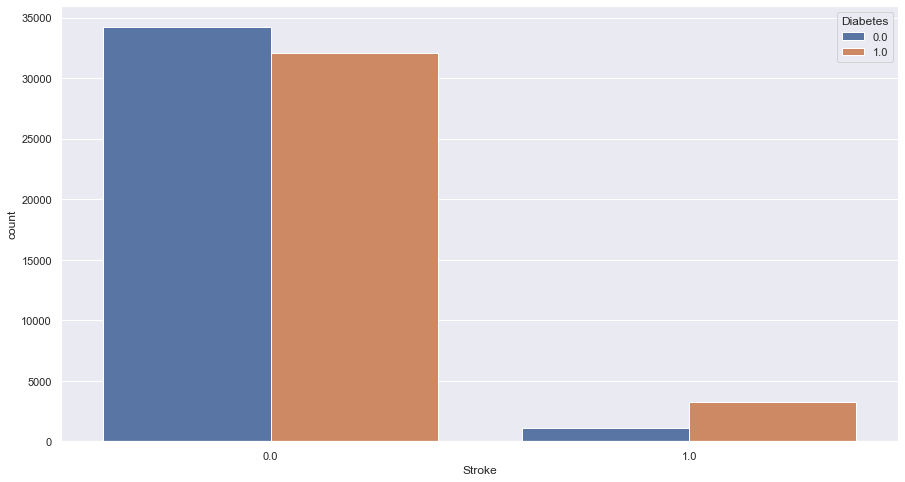

In [25]:
plt.figure(figsize=(15,8))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.countplot(data=df, x='Stroke', hue='Diabetes')
plt.show()

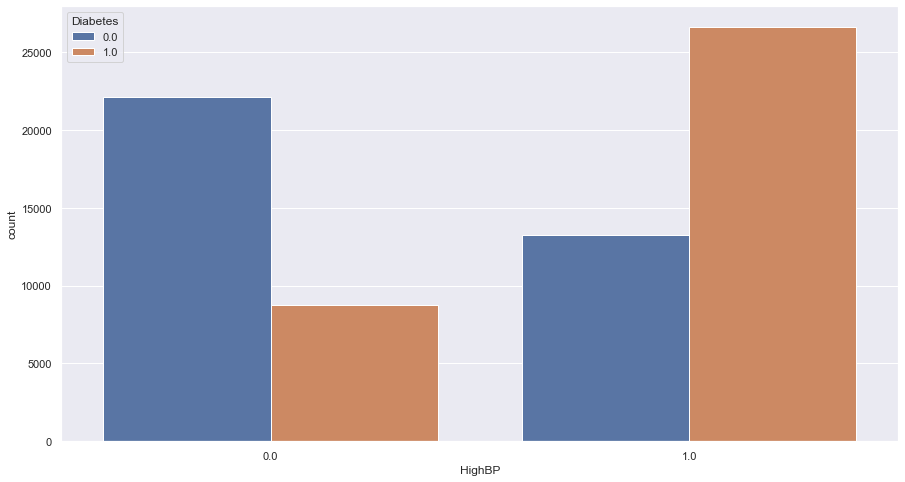

In [26]:
plt.figure(figsize=(15,8))
sns.set_style('whitegrid')
sns.set_theme(style="darkgrid")
sns.countplot(data=df, x='HighBP', hue='Diabetes')
plt.show()

# Checking Data Distribution

In [27]:
def check_data_distribution(df):
    plt.figure(figsize=(20,25))
    
    for i,col in enumerate(df):
        plt.subplot(7,3,i + 1)
        sns.histplot(df[col], kde=False, bins= 10)
    plt.tight_layout()
    plt.show()

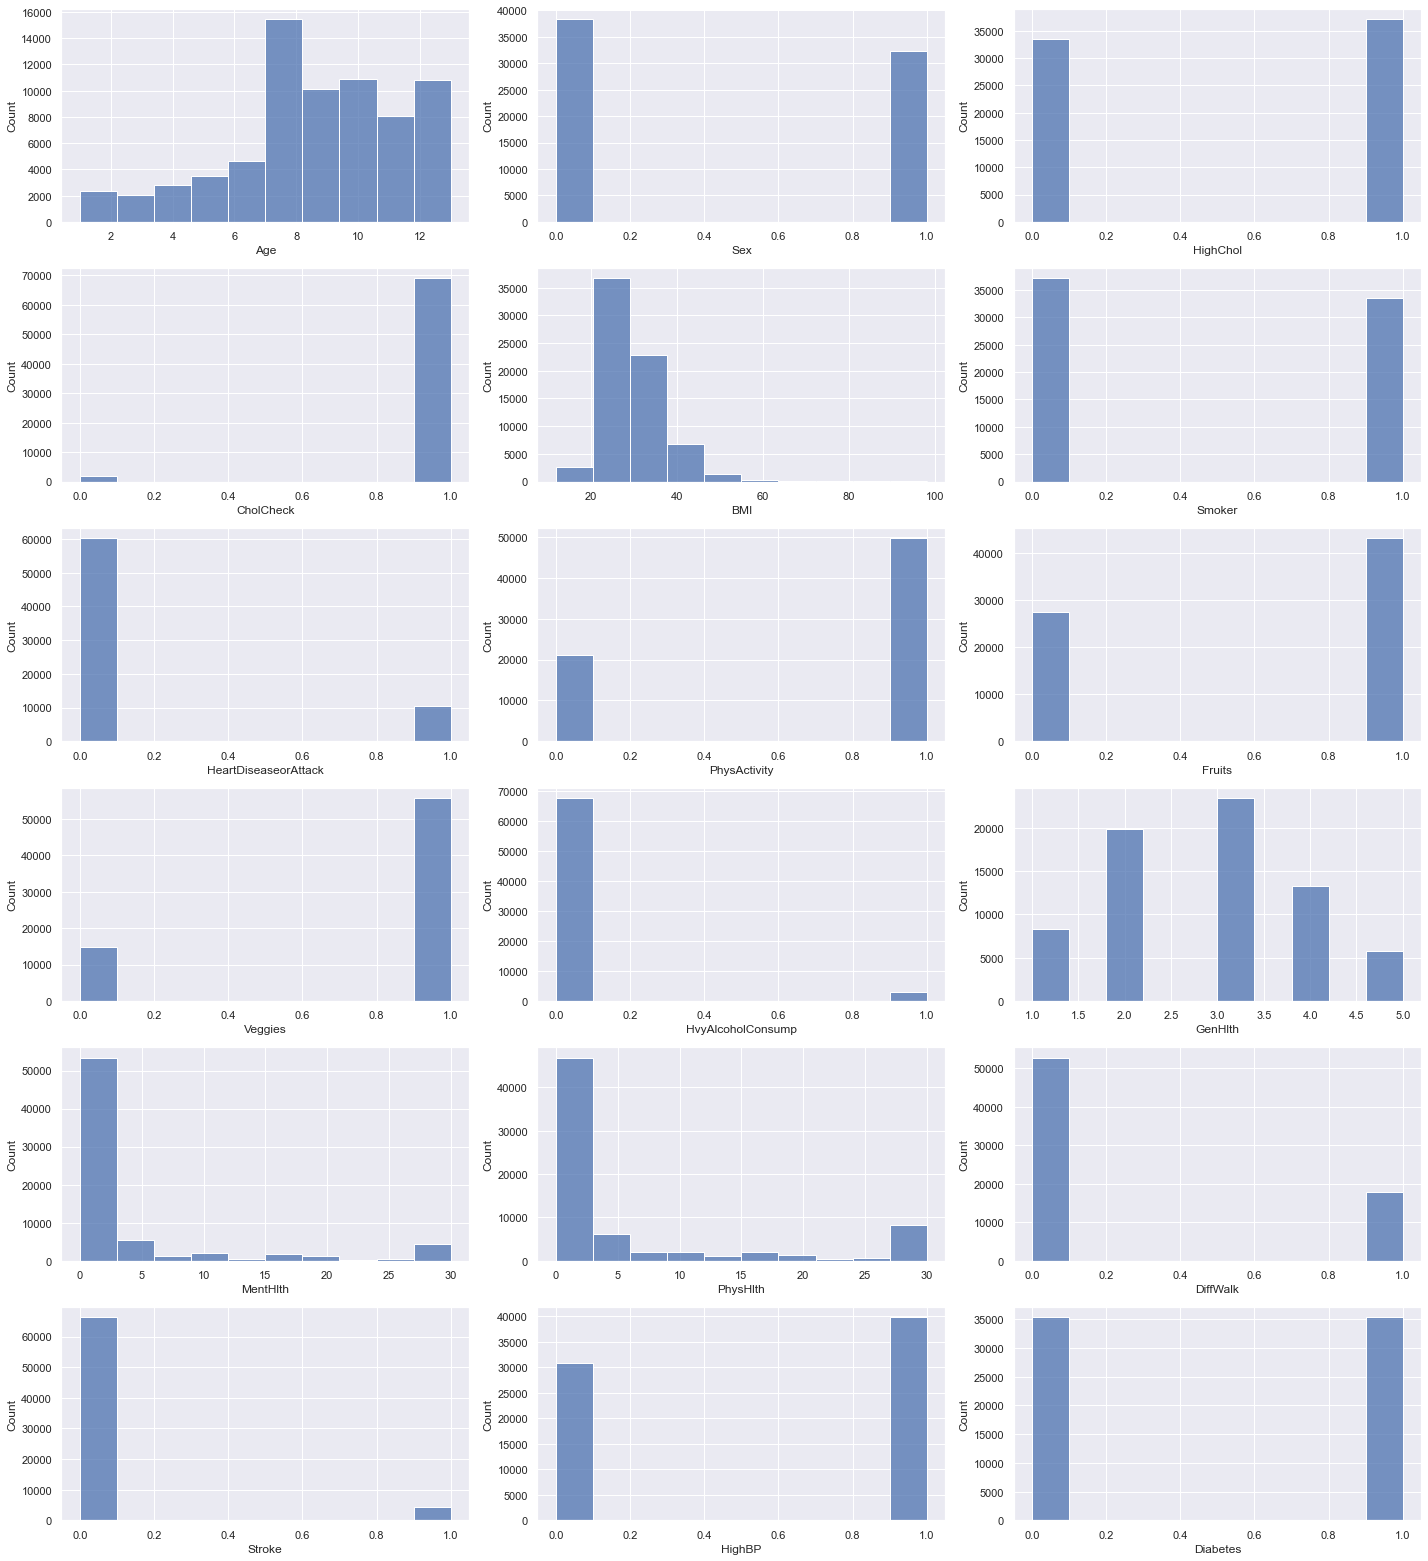

In [28]:
check_data_distribution(df)

# Checking Outlier

In [29]:
def check_outlier(df):
    plt.figure(figsize=(20,25))
    
    for i,col in enumerate(df):
        plt.subplot(6,4,i + 1)
        sns.boxplot(y=col, data=df, color='b')
    plt.tight_layout()
    plt.show()

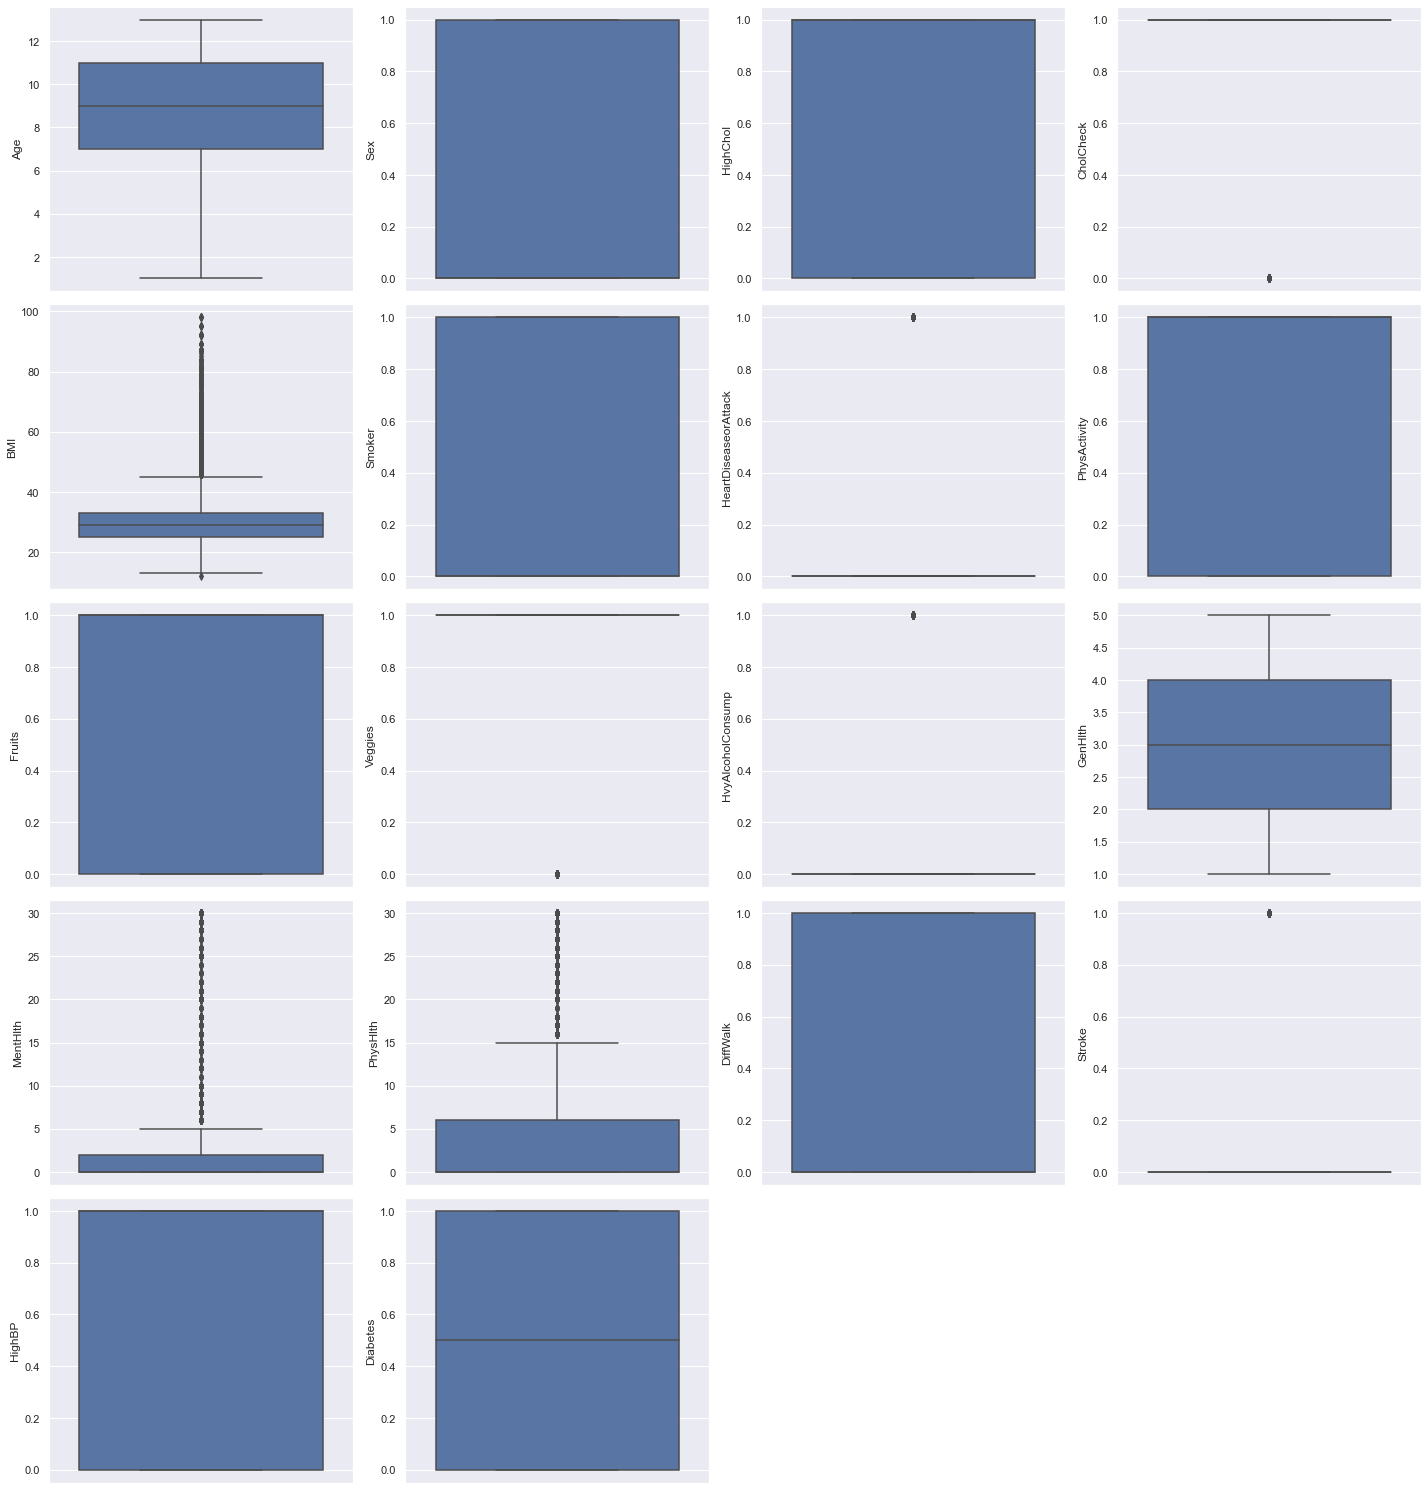

There are outlier in BMI, MentHlth and PhysHlth


In [30]:
check_outlier(df)
print('There are outlier in BMI, MentHlth and PhysHlth')

# Feature Engineering

Removing outliers

In [1]:
def handle_outlier(df, colm):
    for i in colm:
        Q1 = df[colm].quantile(0.25)
        Q3 = df[colm].quantile(0.75)
        IQR = Q3 - Q1
        upper_limit = Q3 + 1.5 * IQR
        lower_limit = Q1 - 1.5 * IQR
        df[df[colm] > upper_limit]
        df[df[colm] < lower_limit]
        df[colm] = np.where(
        df[colm] > upper_limit,
        upper_limit,
        np.where(
            df[colm] < lower_limit,
            lower_limit,
            df[colm]
        )
    )

In [32]:
handle_outlier(df, ['MentHlth', 'PhysHlth', 'BMI'])

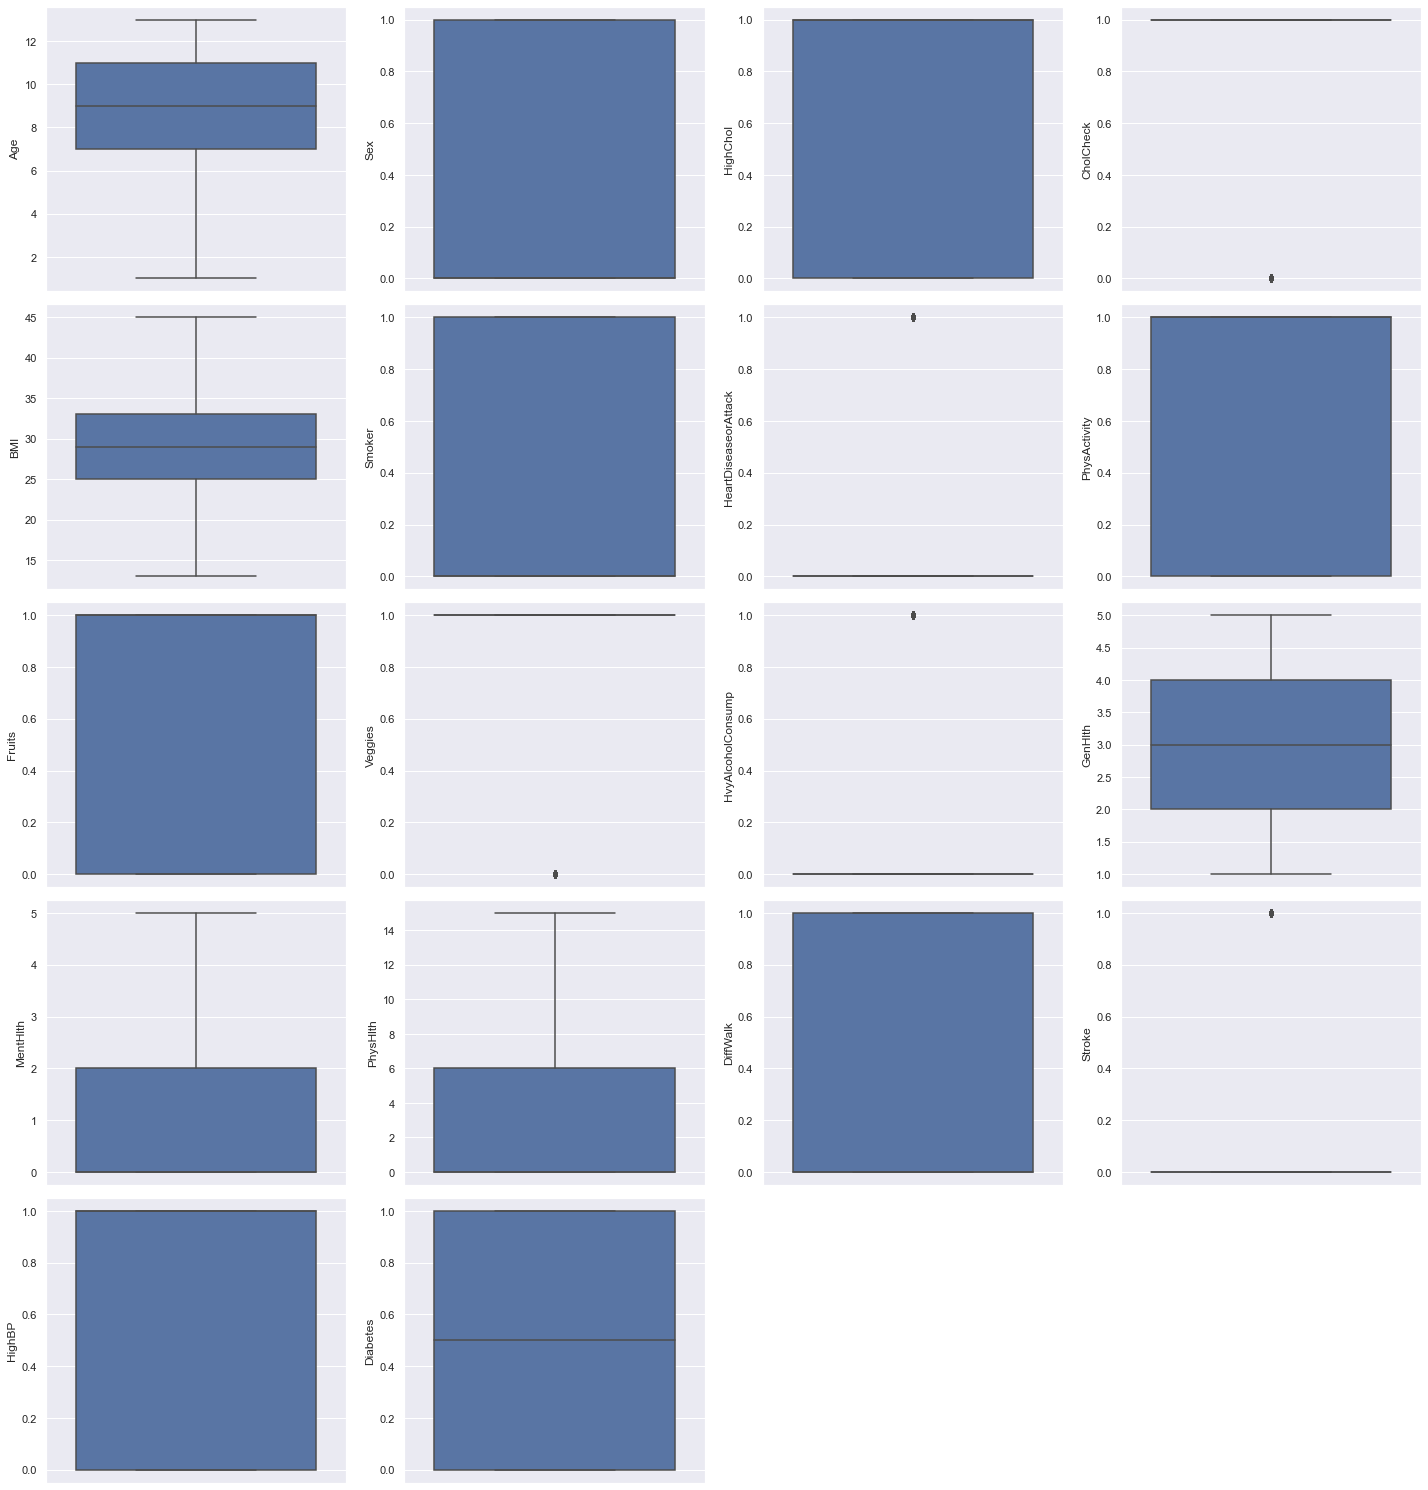

There is not outlier.


In [33]:
check_outlier(df)
print('There is not outlier.')

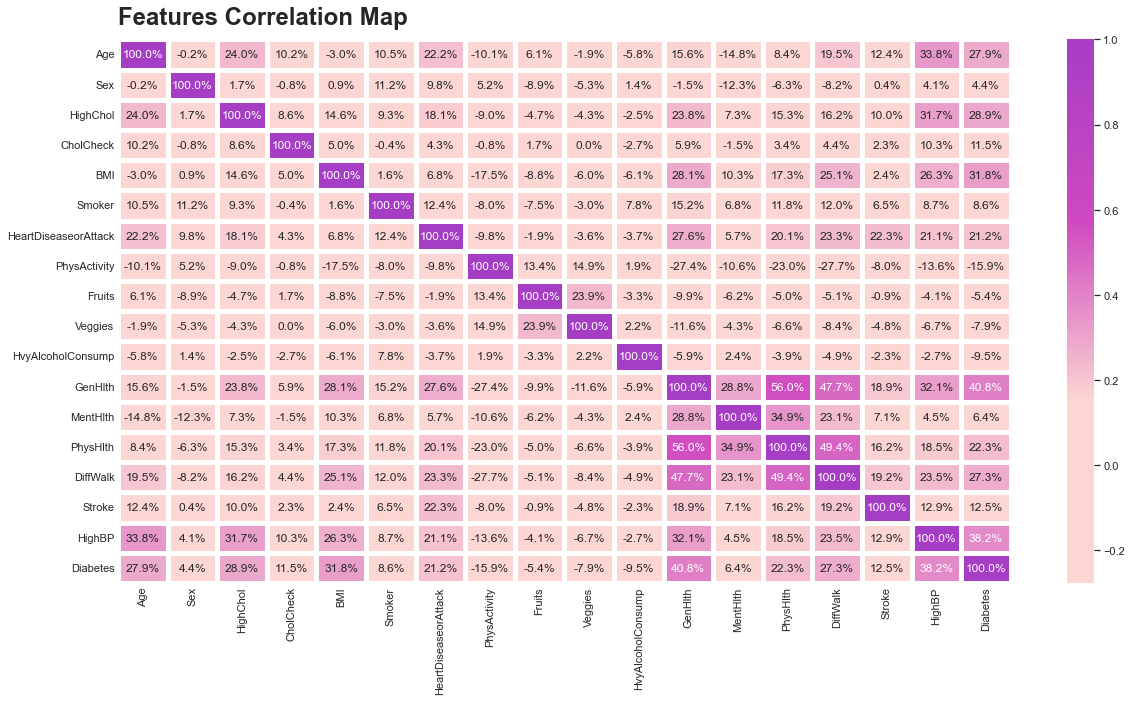

In [34]:
fig,ax=plt.subplots(1,1,figsize=(20,10))
colors = ['#FBD6D2',"#FBD6D2", "#CE49BF","#A63EC5"]
colormap = matplotlib.colors.LinearSegmentedColormap.from_list("", colors)
sns.heatmap(df.corr(),annot=True,ax=ax,cmap=colormap,fmt='.1%',linewidth=5)
ax.tick_params(axis='both',which='both',length=0)
ax.text(0,-0.5,'Features Correlation Map',fontsize=24, fontweight='bold');

# Spliting data into X and y

In [35]:
X = df.drop(['Diabetes'], axis=1)
y = df['Diabetes']

# Training the Model

In [36]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=0)

In [37]:
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((56553, 17), (56553,), (14139, 17), (14139,))

# Model Building without feature selection

In [38]:
def model_building(modelname, X_train, X_test, y_train, y_test):
    if modelname == 'logistic':
        ls = LogisticRegression(max_iter=500)
        ls.fit(X_train, y_train)
        y_pred = ls.predict(X_test)
        ls.score(X_train, y_train)
        accuracy_score(y_test, y_pred)
        print(classification_report(y_test, y_pred))
        
    elif modelname == 'RF':
        rf = RandomForestClassifier()
        rf.fit(X_train, y_train)
        scores = cross_val_score(rf, X_train, y_train, cv=5)
        rf_pred = rf.predict(X_test)
        print("Average cross validation score: {:.3f}".format(scores.mean()))
        print("Test accuracy: {:.3f}".format(rf.score(X_test, y_test)))
        print("F1 score: {:.3f}".format(f1_score(y_test, rf_pred)))
        print(confusion_matrix(y_test, rf_pred))
        print(classification_report(y_test, rf_pred))
        
    elif modelname == 'DT':
        dt = DecisionTreeClassifier()
        dt.fit(X_train, y_train)
        scores = cross_val_score(dt, X_train, y_train, cv=5)
        dt_pred = dt.predict(X_test)
        print("Average cross validation score: {:.3f}".format(scores.mean()))
        print("Test accuracy: {:.3f}".format(dt.score(X_test, y_test)))
        print("F1 score: {:.3f}".format(f1_score(y_test, dt_pred)))
        print(confusion_matrix(y_test, dt_pred))
        print(classification_report(y_test, dt_pred))
        

In [39]:
model_building('logistic', X_train, X_test, y_train, y_test)

              precision    recall  f1-score   support

         0.0       0.75      0.73      0.74      6932
         1.0       0.75      0.77      0.76      7207

    accuracy                           0.75     14139
   macro avg       0.75      0.75      0.75     14139
weighted avg       0.75      0.75      0.75     14139



In [40]:
model_building('RF', X_train, X_test, y_train, y_test)

Average cross validation score: 0.724
Test accuracy: 0.729
F1 score: 0.741
[[4838 2094]
 [1734 5473]]
              precision    recall  f1-score   support

         0.0       0.74      0.70      0.72      6932
         1.0       0.72      0.76      0.74      7207

    accuracy                           0.73     14139
   macro avg       0.73      0.73      0.73     14139
weighted avg       0.73      0.73      0.73     14139



In [41]:
model_building('DT', X_train, X_test, y_train, y_test)

Average cross validation score: 0.658
Test accuracy: 0.656
F1 score: 0.654
[[4685 2247]
 [2610 4597]]
              precision    recall  f1-score   support

         0.0       0.64      0.68      0.66      6932
         1.0       0.67      0.64      0.65      7207

    accuracy                           0.66     14139
   macro avg       0.66      0.66      0.66     14139
weighted avg       0.66      0.66      0.66     14139



In [42]:
"""scores = cross_val_score(ls, X_train, y_train, cv=5)
logreg_pred = ls.predict(X_test)
print("Average cross validation score: {:.3f}".format(scores.mean()))
print("Test accuracy: {:.3f}".format(ls.score(X_test, y_test)))
print("F1 score: {:.3f}".format(f1_score(y_test, logreg_pred)))
print(confusion_matrix(y_test, logreg_pred))
print(classification_report(y_test, logreg_pred))"""

'scores = cross_val_score(ls, X_train, y_train, cv=5)\nlogreg_pred = ls.predict(X_test)\nprint("Average cross validation score: {:.3f}".format(scores.mean()))\nprint("Test accuracy: {:.3f}".format(ls.score(X_test, y_test)))\nprint("F1 score: {:.3f}".format(f1_score(y_test, logreg_pred)))\nprint(confusion_matrix(y_test, logreg_pred))\nprint(classification_report(y_test, logreg_pred))'

# Model Building with feature selection

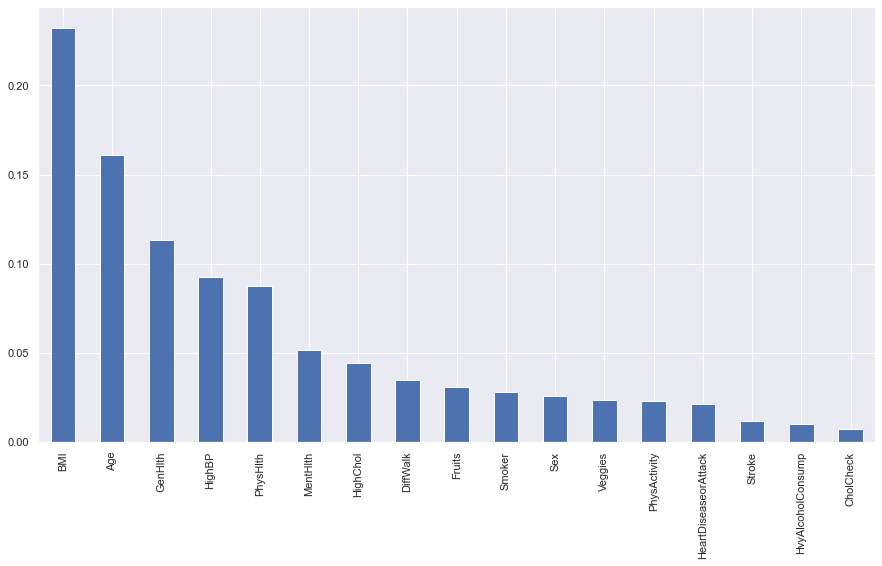

In [43]:
model = ExtraTreesClassifier()
model.fit(X,y)
plt.figure(figsize=(15,8))
feature_importance = pd.Series(model.feature_importances_, index= X.columns)
feature_importance.nlargest(20).plot(kind='bar')
plt.show()

In [44]:
drop_col = df.drop(columns=['Stroke', 'HvyAlcoholConsump', 'CholCheck'], axis=1)

In [45]:
X = drop_col.drop('Diabetes', axis=1)
y = drop_col['Diabetes']

In [46]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=0)

In [47]:
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((56553, 14), (56553,), (14139, 14), (14139,))

# Hyperparameter tuning

In [48]:
param_grid = [    
    {'penalty' : ['l1', 'l2', 'elasticnet', 'none'],
    'C' : np.logspace(-4, 4, 20),
    'solver' : ['lbfgs','newton-cg','liblinear','sag','saga'],
    'max_iter' : [100, 1000,2500, 5000]
    }
]

In [49]:
#clf = GridSearchCV(ls, param_grid = param_grid, cv = 3, verbose=True, n_jobs=-1)
#best_clf = clf.fit(X_train,y_train)
#best_clf.best_estimator_

In [50]:
ls = LogisticRegression(C=0.012742749857031334, max_iter=1000, penalty='l1', solver='saga')
ls.fit(X_train, y_train)
scores = cross_val_score(ls, X_train, y_train, cv=5)
logreg_pred = ls.predict(X_test)
print("Average cross validation score: {:.3f}".format(scores.mean()))
print("Test accuracy: {:.3f}".format(ls.score(X_test, y_test)))
print("F1 score: {:.3f}".format(f1_score(y_test, logreg_pred)))
print(confusion_matrix(y_test, logreg_pred))
print(classification_report(y_test, logreg_pred))

Average cross validation score: 0.745
Test accuracy: 0.744
F1 score: 0.752
[[5021 1911]
 [1711 5496]]
              precision    recall  f1-score   support

         0.0       0.75      0.72      0.73      6932
         1.0       0.74      0.76      0.75      7207

    accuracy                           0.74     14139
   macro avg       0.74      0.74      0.74     14139
weighted avg       0.74      0.74      0.74     14139



# Standardization using StandardScaler

In [51]:
sc = StandardScaler()
X_train_std = sc.fit_transform(X)

In [52]:
X_train_std, X_test_std, y_train_std, y_test_std = train_test_split(X_train_std, y, test_size=0.30, random_state=0)

In [53]:
ls = LogisticRegression(C=0.012742749857031334, max_iter=1000, penalty='l1', solver='saga')
ls.fit(X_train_std, y_train_std)
scores = cross_val_score(ls, X_train_std, y_train_std, cv=5)
logreg_pred = ls.predict(X_test_std)
print("Average cross validation score: {:.3f}".format(scores.mean()))
print("Test accuracy: {:.3f}".format(ls.score(X_test_std, y_test_std)))
print("F1 score: {:.3f}".format(f1_score(y_test_std, logreg_pred)))
print(confusion_matrix(y_test_std, logreg_pred))
print(classification_report(y_test_std, logreg_pred))

Average cross validation score: 0.745
Test accuracy: 0.745
F1 score: 0.752
[[7575 2906]
 [2504 8223]]
              precision    recall  f1-score   support

         0.0       0.75      0.72      0.74     10481
         1.0       0.74      0.77      0.75     10727

    accuracy                           0.74     21208
   macro avg       0.75      0.74      0.74     21208
weighted avg       0.75      0.74      0.74     21208



In [54]:
sc = StandardScaler()
X_train_std = sc.fit_transform(X)

In [55]:
X_train_std, X_test_std, y_train_std, y_test_std = train_test_split(X_train_std, y, test_size=0.30, random_state=0)

In [56]:
ls = LogisticRegression(C=0.08858667904100823, max_iter=1000, penalty='l1', solver='liblinear')
ls.fit(X_train_std, y_train_std)
scores = cross_val_score(ls, X_train_std, y_train_std, cv=5)
logreg_pred = ls.predict(X_test_std)
print("Average cross validation score: {:.3f}".format(scores.mean()))
print("Test accuracy: {:.3f}".format(ls.score(X_test_std, y_test_std)))
print("F1 score: {:.3f}".format(f1_score(y_test_std, logreg_pred)))
print(confusion_matrix(y_test_std, logreg_pred))
print(classification_report(y_test_std, logreg_pred))

Average cross validation score: 0.745
Test accuracy: 0.745
F1 score: 0.753
[[7573 2908]
 [2498 8229]]
              precision    recall  f1-score   support

         0.0       0.75      0.72      0.74     10481
         1.0       0.74      0.77      0.75     10727

    accuracy                           0.75     21208
   macro avg       0.75      0.74      0.74     21208
weighted avg       0.75      0.75      0.74     21208



In [57]:
xgb_cv = XGBClassifier(n_estimators=100)
scores = cross_val_score(xgb_cv, X_train_std, y_train_std, cv=10, scoring = "accuracy")

[12:21:24] WARNING: /opt/concourse/worker/volumes/live/7a2b9f41-3287-451b-6691-43e9a6c0910f/volume/xgboost-split_1619728204606/work/src/learner.cc:1061: Starting in XGBoost 1.3.0, the default evaluation metric used with the objective 'binary:logistic' was changed from 'error' to 'logloss'. Explicitly set eval_metric if you'd like to restore the old behavior.
[12:21:25] WARNING: /opt/concourse/worker/volumes/live/7a2b9f41-3287-451b-6691-43e9a6c0910f/volume/xgboost-split_1619728204606/work/src/learner.cc:1061: Starting in XGBoost 1.3.0, the default evaluation metric used with the objective 'binary:logistic' was changed from 'error' to 'logloss'. Explicitly set eval_metric if you'd like to restore the old behavior.
[12:21:26] WARNING: /opt/concourse/worker/volumes/live/7a2b9f41-3287-451b-6691-43e9a6c0910f/volume/xgboost-split_1619728204606/work/src/learner.cc:1061: Starting in XGBoost 1.3.0, the default evaluation metric used with the objective 'binary:logistic' was changed from 'error' t

In [58]:
print("Scores:", scores)
print("Mean:", scores.mean())
print("Standard Deviation:", scores.std())

Scores: [0.7433825  0.73408769 0.74722166 0.74600929 0.73241714 0.74595796
 0.73827809 0.74070331 0.74373484 0.74676637]
Mean: 0.7418558872038854
Standard Deviation: 0.0050636652317663225


In [59]:
params = {
    'n_estimators': [100, 200, 500],
    'learning_rate': [0.01,0.05,0.1],
    'booster': ['gbtree', 'gblinear'],
    'gamma': [0, 0.5, 1],
    'reg_alpha': [0, 0.5, 1],
    'reg_lambda': [0.5, 1, 5],
    'base_score': [0.2, 0.5, 1]
}

In [60]:
#gs2 = GridSearchCV(XGBClassifier(n_jobs=-1), params, n_jobs=-1, cv=KFold(n_splits=3), scoring='roc_auc')
#gs2.fit(X_train_std, y_train_std)

In [61]:
#print('Best score:', gs2.best_score_)
#print('Best score:', gs2.best_params_)